# Fuel Consumption Task in Class

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



## Upload DataSet

In [2]:
df=pd.read_csv("FuelConsumption.csv")

In [3]:
df

,Year,MAKE,MODEL,VEHICLE CLASS,ENGINE SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL CONSUMPTION,COEMISSIONS
0,2000,ACURA,1.6EL,COMPACT,1.6,4,A4,X,10.5,216
1,2000,ACURA,1.6EL,COMPACT,1.6,4,M5,X,9.8,205
2,2000,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.7,265
3,2000,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0,301
4,2000,ACURA,INTEGRA,SUBCOMPACT,1.8,4,A4,X,11.4,230
...,...,...,...,...,...,...,...,...,...,...
634,2000,VOLVO,V70 AWD TURBO,STATION WAGON - MID-SIZE,2.4,5,A4,Z,14.4,288
635,2000,VOLVO,V70 GLT TURBO,STATION WAGON - MID-SIZE,2.4,5,A4,Z,13.6,274
636,2000,VOLVO,V70 T5 TURBO,STATION WAGON - MID-SIZE,2.3,5,A4,Z,13.9,274
637,2000,VOLVO,V70 T5 TURBO,STATION WAGON - MID-SIZE,2.3,5,M5,Z,13.0,260


#### Checking Head or Tail of the DataSet

In [4]:
df.head(5)

,Year,MAKE,MODEL,VEHICLE CLASS,ENGINE SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL CONSUMPTION,COEMISSIONS
0,2000,ACURA,1.6EL,COMPACT,1.6,4,A4,X,10.5,216
1,2000,ACURA,1.6EL,COMPACT,1.6,4,M5,X,9.8,205
2,2000,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.7,265
3,2000,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0,301
4,2000,ACURA,INTEGRA,SUBCOMPACT,1.8,4,A4,X,11.4,230


In [5]:
df.tail(5)

,Year,MAKE,MODEL,VEHICLE CLASS,ENGINE SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL CONSUMPTION,COEMISSIONS
634,2000,VOLVO,V70 AWD TURBO,STATION WAGON - MID-SIZE,2.4,5,A4,Z,14.4,288
635,2000,VOLVO,V70 GLT TURBO,STATION WAGON - MID-SIZE,2.4,5,A4,Z,13.6,274
636,2000,VOLVO,V70 T5 TURBO,STATION WAGON - MID-SIZE,2.3,5,A4,Z,13.9,274
637,2000,VOLVO,V70 T5 TURBO,STATION WAGON - MID-SIZE,2.3,5,M5,Z,13.0,260
638,2000,VOLVO,V70R AWD TURBO,STATION WAGON - MID-SIZE,2.4,5,A5,Z,14.7,299


In [6]:
df.columns

Index(['Year', 'MAKE', 'MODEL', 'VEHICLE CLASS', 'ENGINE SIZE', 'CYLINDERS',
       'TRANSMISSION', 'FUEL', 'FUEL CONSUMPTION', 'COEMISSIONS '],
      dtype='object')

#### Checking Info of the DataSet

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 639 entries, 0 to 638
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Year              639 non-null    int64  
 1   MAKE              639 non-null    object 
 2   MODEL             639 non-null    object 
 3   VEHICLE CLASS     639 non-null    object 
 4   ENGINE SIZE       639 non-null    float64
 5   CYLINDERS         639 non-null    int64  
 6   TRANSMISSION      639 non-null    object 
 7   FUEL              639 non-null    object 
 8   FUEL CONSUMPTION  639 non-null    float64
 9   COEMISSIONS       639 non-null    int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 50.1+ KB


In [8]:
df.describe()

,Year,ENGINE SIZE,CYLINDERS,FUEL CONSUMPTION,COEMISSIONS
count,639.0,639.000000,639.000000,639.000000,639.000000
mean,2000.0,3.265728,5.805947,14.713615,296.809077
std,0.0,1.231012,1.625588,3.307044,65.504178
min,2000.0,1.000000,3.000000,4.900000,104.000000
25%,2000.0,2.200000,4.000000,12.500000,253.000000
50%,2000.0,3.000000,6.000000,14.400000,288.000000
75%,2000.0,4.300000,6.000000,16.600000,343.000000
max,2000.0,8.000000,12.000000,30.200000,582.000000


#### Check number of rows and columns

In [9]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 639
Columns: 10


#### Check data types of all columns

In [10]:
df.dtypes

Year                  int64
MAKE                 object
MODEL                object
VEHICLE CLASS        object
ENGINE SIZE         float64
CYLINDERS             int64
TRANSMISSION         object
FUEL                 object
FUEL CONSUMPTION    float64
COEMISSIONS           int64
dtype: object

#### Check missing values


In [11]:
df.isnull().sum()

Year                0
MAKE                0
MODEL               0
VEHICLE CLASS       0
ENGINE SIZE         0
CYLINDERS           0
TRANSMISSION        0
FUEL                0
FUEL CONSUMPTION    0
COEMISSIONS         0
dtype: int64

#### Check duplicate rows


In [12]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1


#### Remove duplicate rows


In [13]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (638, 10)


#### Check number of unique values in each column


In [14]:
df.nunique()

Year                  1
MAKE                 36
MODEL               328
VEHICLE CLASS        14
ENGINE SIZE          40
CYLINDERS             7
TRANSMISSION          8
FUEL                  5
FUEL CONSUMPTION    124
COEMISSIONS         116
dtype: int64

#### Check unique vehicle classes


In [15]:
df["VEHICLE CLASS"].unique()

array(['COMPACT', 'MID-SIZE', 'SUBCOMPACT', 'STATION WAGON - MID-SIZE',
       'MINICOMPACT', 'TWO-SEATER', 'STATION WAGON - SMALL', 'FULL-SIZE',
       'SUV', 'VAN - CARGO', 'VAN - PASSENGER', 'PICKUP TRUCK - STANDARD',
       'PICKUP TRUCK - SMALL', 'MINIVAN'], dtype=object)

#### Check unique fuel types


In [16]:
df["FUEL"].unique()

array(['X', 'Z', 'E', 'N', 'D'], dtype=object)

#### Check unique transmission types


In [17]:
df["TRANSMISSION"].unique()

array(['A4', 'M5', 'AS5', 'AS4', 'M6', 'A5', 'A3', 'AS6'], dtype=object)

# EDA — Exploratory Data Analysis

#### Select numerical columns


In [18]:
numeric_columns = df.select_dtypes(include=np.number).columns
print(numeric_columns)

Index(['Year', 'ENGINE SIZE', 'CYLINDERS', 'FUEL CONSUMPTION', 'COEMISSIONS '], dtype='object')


#### Select categorical columns


In [19]:
categorical_columns = df.select_dtypes(include="object").columns
print(categorical_columns)

Index(['MAKE', 'MODEL', 'VEHICLE CLASS', 'TRANSMISSION', 'FUEL'], dtype='object')


#### Distribution of Engine Size

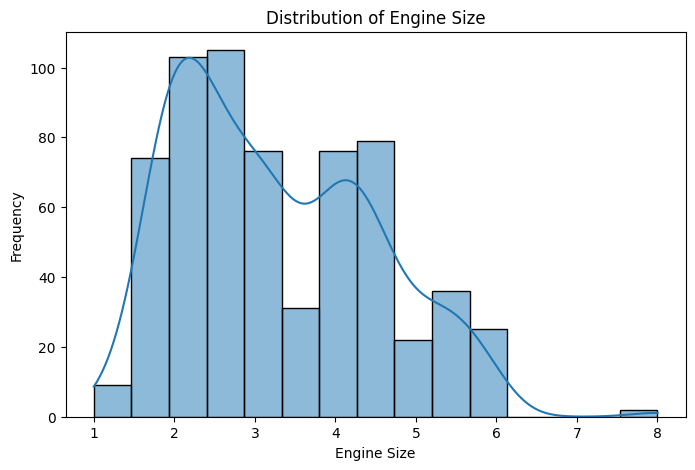

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(df["ENGINE SIZE"], kde=True)

plt.title("Distribution of Engine Size")
plt.xlabel("Engine Size")
plt.ylabel("Frequency")
plt.show()

#### Distribution of Fuel Consumption

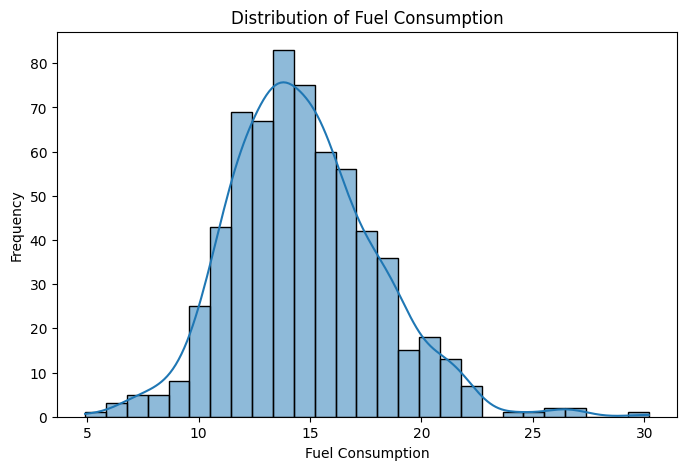

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(df["FUEL CONSUMPTION"], kde=True)

plt.title("Distribution of Fuel Consumption")
plt.xlabel("Fuel Consumption")
plt.ylabel("Frequency")
plt.show()

#### Engine Size Boxplot

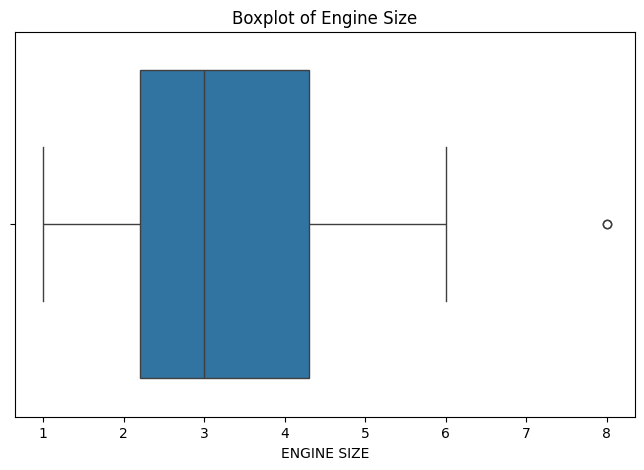

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["ENGINE SIZE"])

plt.title("Boxplot of Engine Size")
plt.show()

#### Fuel Consumption BoxPlot

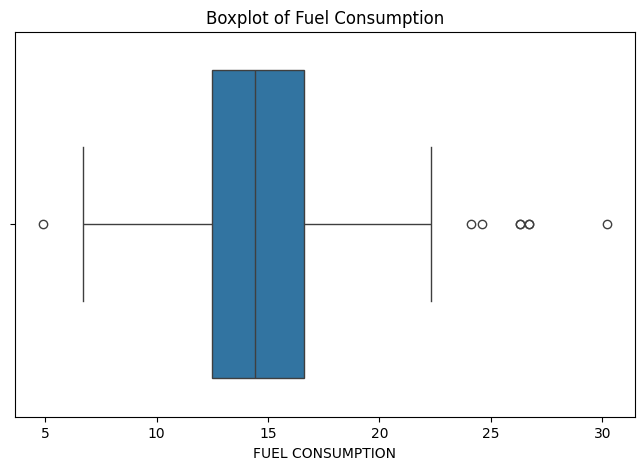

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["FUEL CONSUMPTION"])

plt.title("Boxplot of Fuel Consumption")
plt.show()

#### Cylinders Count

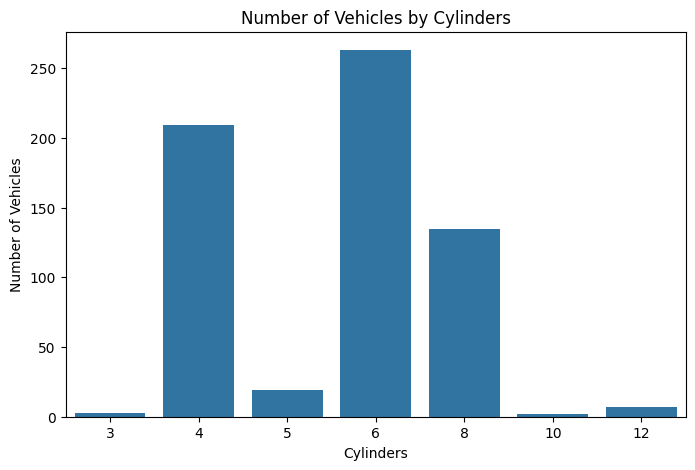

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(x=df["CYLINDERS"])

plt.title("Number of Vehicles by Cylinders")
plt.xlabel("Cylinders")
plt.ylabel("Number of Vehicles")
plt.show()

#### Vehicle Class Distribution

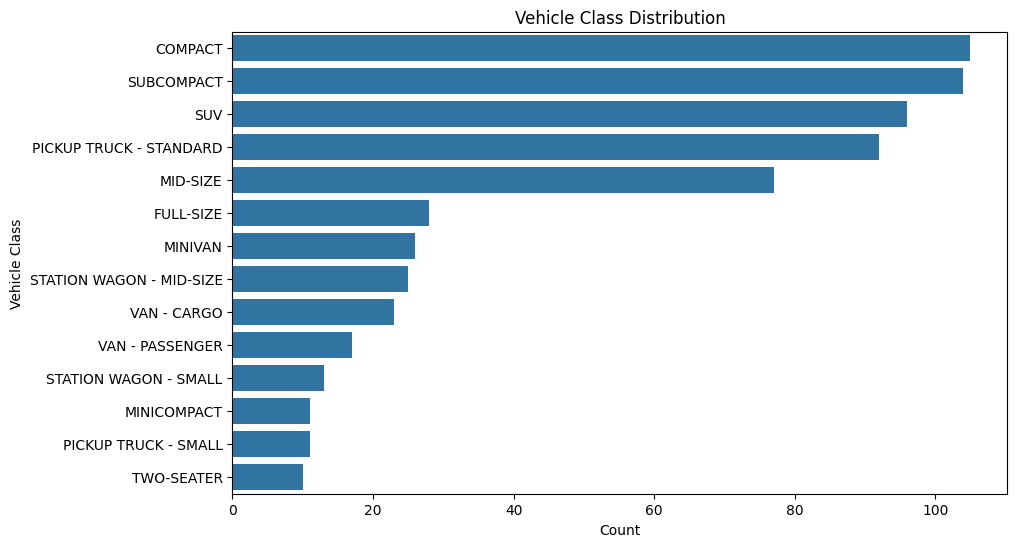

In [25]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="VEHICLE CLASS",
    order=df["VEHICLE CLASS"].value_counts().index
)

plt.title("Vehicle Class Distribution")
plt.xlabel("Count")
plt.ylabel("Vehicle Class")
plt.show()

#### Fuel Type Distribution

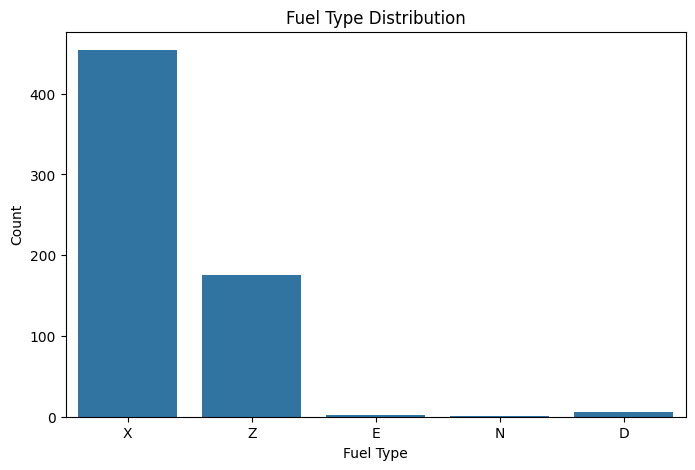

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="FUEL")

plt.title("Fuel Type Distribution")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.show()

#### Correlation Matrix

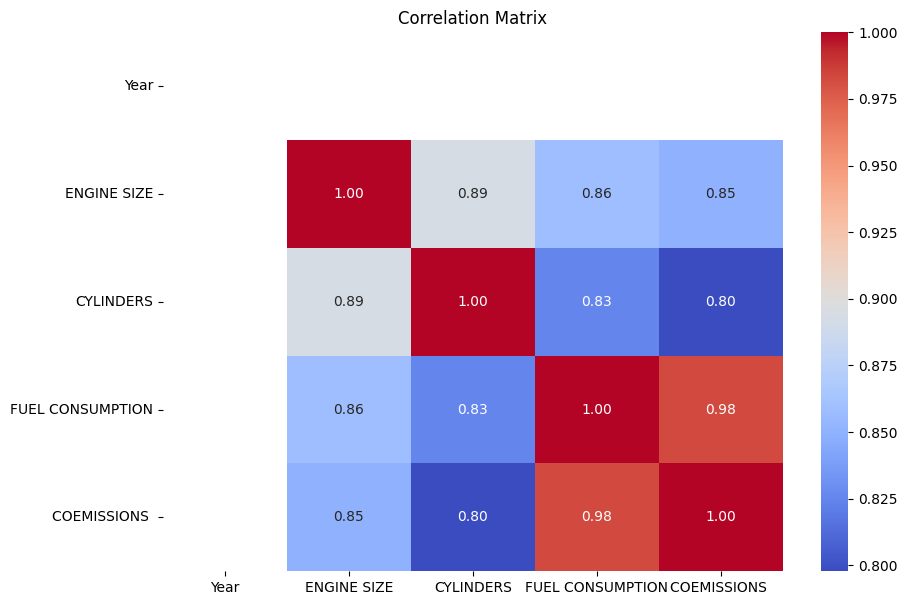

In [27]:
# Correlation between numerical variables

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

#### Engine Size and Fuel Consumption

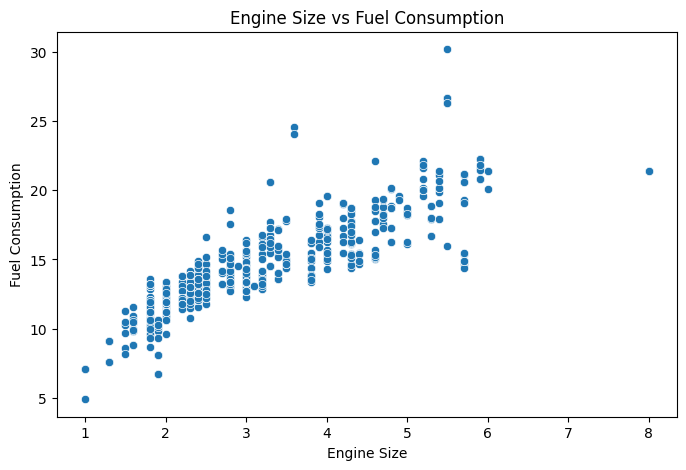

In [28]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="ENGINE SIZE",
    y="FUEL CONSUMPTION"
)

plt.title("Engine Size vs Fuel Consumption")
plt.xlabel("Engine Size")
plt.ylabel("Fuel Consumption")
plt.show()

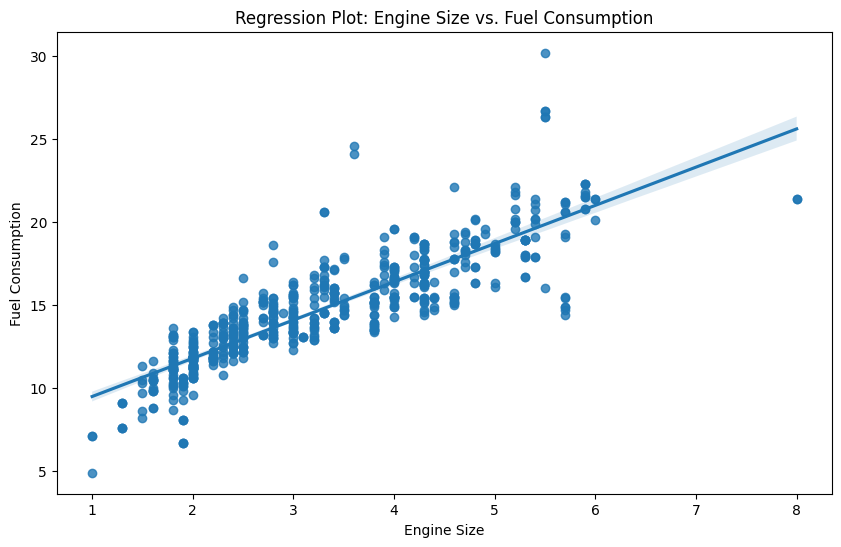

In [29]:
plt.figure(figsize=(10, 6))
sns.regplot(x='ENGINE SIZE', y='FUEL CONSUMPTION', data=df)
plt.title('Regression Plot: Engine Size vs. Fuel Consumption')
plt.xlabel('Engine Size')
plt.ylabel('Fuel Consumption')
plt.show()

## Linear Regression

## Create Linear Regression Model

In [30]:
# Remove extra spaces from column names

df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Year', 'MAKE', 'MODEL', 'VEHICLE CLASS', 'ENGINE SIZE', 'CYLINDERS', 'TRANSMISSION', 'FUEL', 'FUEL CONSUMPTION', 'COEMISSIONS']


In [31]:
# All Features + Encoding + Linear Regression

# -----------------------------
# 1. Features and Target
# -----------------------------

X = df.drop(columns=["COEMISSIONS"])
y = df["COEMISSIONS"]

# -----------------------------
# 2. Identify Column Types
# -----------------------------

categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(exclude=["object"]).columns

print("Categorical Features:")
print(list(categorical_features))

print("\nNumerical Features:")
print(list(numerical_features))

# -----------------------------
# 3. Preprocessing / Encoding
# -----------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# -----------------------------
# 4. Create Pipeline
# -----------------------------

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# -----------------------------
# 5. Train-Test Split
# -----------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# -----------------------------
# 6. Train Model
# -----------------------------

model.fit(X_train, y_train)

# -----------------------------
# 7. Prediction
# -----------------------------

y_pred = model.predict(X_test)

# -----------------------------
# 8. Evaluation
# -----------------------------

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nModel Results")
print("-----------------------------")
print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Categorical Features:
['MAKE', 'MODEL', 'VEHICLE CLASS', 'TRANSMISSION', 'FUEL']

Numerical Features:
['Year', 'ENGINE SIZE', 'CYLINDERS', 'FUEL CONSUMPTION']

Model Results
-----------------------------
Mean Squared Error: 31.995696861557665
Mean Absolute Error: 3.9816433207383746
R2 Score: 0.9923313877761697


In [33]:
import joblib

# Save
joblib.dump(model, "model.pkl")
print("✅ Model saved!")

# Load
loaded_model = joblib.load("model.pkl")

# Verify
y_pred_loaded = loaded_model.predict(X_test)
print("Original R2:", r2_score(y_test, y_pred))
print("Loaded  R2:", r2_score(y_test, y_pred_loaded))

✅ Model saved!
Original R2: 0.9923313877761697
Loaded  R2: 0.9923313877761697
